<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-scientific-discovery/blob/main/notebooks/lecture-10/dqn-lunar-lander.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

# Deep Q-learning on the Lunar Lander

*Deep Learning for Scientific Discovery, Jagiellonian University. Author: Marcin Płodzień.*

### From a table to a network

Tabular Q-learning stores one number $Q(s,a)$ for every state and action and moves it towards the target $r+\gamma\max_{a'}Q(s',a')$ after every transition. A gridworld with 22 non-terminal states and 4 moves needs $22\times4=88$ action values. A lander is described by its position, velocity, angle and angular velocity, eight real numbers that never repeat exactly, so no table can hold its action values. Two states that differ in the fifth decimal of the velocity should also have almost the same values, and a table cannot express this.

### A neural network as the action-value function

A neural network $Q_\theta(s,\cdot)$ takes the state as input and returns one number per action. Its parameters $\theta$ replace the table, and nearby states automatically get similar values. The Q-learning update becomes a regression. The target $y=r+\gamma\max_{a'}Q(s',a')$ plays the role of the label, and the network is trained to reduce the squared difference between $Q_\theta(s,a)$ and $y$. This combination of Q-learning and a deep network, together with two devices that stabilise the training, was introduced by Mnih and coworkers, who trained one network architecture on 49 Atari games from the screen pixels [V. Mnih *et al.*, Nature **518**, 529 (2015), [doi:10.1038/nature14236](https://doi.org/10.1038/nature14236)].

### Deep Q-learning on the lander

We introduce the Lunar Lander environment and watch a random agent crash. We then build the deep Q-network (DQN) from the network, the loss, the replay buffer and the target network, train it, and watch stages of the training. We finish with the returns of the trained agent and the control rule that its network has learned.

All random generators are seeded, so every run gives the same numbers.

> **Running this notebook in Google Colab**
> 1. Go to <https://colab.research.google.com> → *File → Upload notebook*.
> 2. Install the environment with `!pip install "gymnasium[box2d]"`. On Colab this may first need `!pip install swig`. PyTorch, `imageio` and `matplotlib` are pre-installed.
> 3. The training runs on the CPU in about twelve minutes. Run the cells in order.

In [1]:
# Imports, colours and the helpers that play an episode and write a video. They only simulate and record.
import os, json, time
os.environ["CUDA_VISIBLE_DEVICES"] = ""          # CPU only
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn
import gymnasium as gym
import imageio
from PIL import Image, ImageDraw, ImageFont
from IPython.display import Video, display

plt.rcParams.update({"font.size": 15, "axes.titlesize": 16, "axes.labelsize": 15, "xtick.labelsize": 13,
                     "ytick.labelsize": 13, "legend.fontsize": 13, "figure.titlesize": 17})
UJNavy, UJBlue, UJSky, DSOrange, UJGray = "#002B5C", "#005CA7", "#3E8FD0", "#D35A05", "#5A6270"
for d in ("figures", "results", "videos"): os.makedirs(d, exist_ok=True)
torch.set_num_threads(4)
SEED = 0
NUMBERS = {}                                     # numbers quoted in the text, written to a file at the end

def save(fig, name):
    fig.savefig(f"figures/{name}.pdf", bbox_inches="tight")
    fig.savefig(f"figures/{name}.png", dpi=150, bbox_inches="tight")

def run_episode(policy, seed, record=False, max_steps=1000):
    # play one episode with policy(state) -> action, return the total reward and, if asked, the rendered frames
    e = gym.make("LunarLander-v3", render_mode="rgb_array" if record else None)
    s, _ = e.reset(seed=seed); total, frames = 0.0, []
    for _ in range(max_steps):
        if record: frames.append(e.render())
        s, r, terminated, truncated, _ = e.step(policy(s))
        total += r
        if terminated or truncated: break
    if record: frames.append(e.render())
    e.close()
    return total, frames

def text_image(width, height, text, size, xy, anchor):
    img = Image.new("RGB", (width, height), (255, 255, 255))
    ImageDraw.Draw(img).text(xy, text, fill=(0, 43, 92), anchor=anchor, font=ImageFont.load_default(size=size))
    return np.asarray(img)

def save_video(policy, seeds, name, min_seconds=16, fps=40):
    # Episodes with the given seeds, one after another until the video lasts min_seconds, one frame per step
    # (the simulation runs at 50 steps per second). A band above the picture shows episode and step, and a white
    # card announces the next episode.
    video = []
    for k, seed in enumerate(seeds, start=1):
        if k > 1: video += [text_image(video[-1].shape[1], video[-1].shape[0], f"episode {k}", 40, (video[-1].shape[1] // 2, video[-1].shape[0] // 2), "mm")] * (fps // 2)
        R, frames = run_episode(policy, seed=seed, record=True)
        band = lambda f, txt: np.vstack([text_image(f.shape[1], 28, txt, 18, (8, 4), "la"), f])
        video += [band(f, f"episode {k}    step {t}") for t, f in enumerate(frames)]
        video += [band(frames[-1], f"episode {k} ended after {len(frames) - 1} steps, return {R:.0f}")] * (fps // 2)
        if len(video) >= min_seconds * fps: break
    imageio.mimsave(f"videos/{name}.mp4", video, fps=fps, macro_block_size=8)
    os.makedirs(f"figures/frames_{name}", exist_ok=True)
    imageio.imwrite(f"figures/frames_{name}/0.png", video[0][::2, ::2])          # still picture of the first frame
    print(f"{name}: {k} episodes, {len(video) / fps:.1f} s")

## The Lunar Lander

The Lunar Lander is a two-dimensional rigid-body simulation in the Box2D physics engine, distributed with the Gymnasium library of reinforcement learning environments [M. Towers *et al.*, Gymnasium, [arXiv:2407.17032](https://arxiv.org/abs/2407.17032)]. A lander starts at the top of the screen with a random push and has to land on a pad between two flags. Gravity pulls it down, and three engines can push it.

| Object | In the Lunar Lander |
|---|---|
| state $s$ | eight numbers, the position $(x,y)$ relative to the pad, the velocities $(v_x,v_y)$, the angle $\varphi$, the angular velocity $\omega$, and two flags that are $1$ when the left or right leg touches the ground |
| action $a$ | one of four, do nothing, fire the left orientation engine, fire the main engine, fire the right orientation engine |
| reward $r$ | after every step, more when the lander moves closer to the pad and slower, less when it tilts, $+10$ for each leg on the ground, $-0.3$ per frame of the main engine and $-0.03$ per frame of a side engine. At the end $+100$ for a safe landing and $-100$ for a crash |
| episode | ends with a crash, when the lander leaves the screen or comes to rest, and after at most 1000 steps |

The rewards are shaped, so the agent gets a signal at every step and not only at the end. A total return of 200 or more counts as a successful landing. The physics is unknown to the agent. It sees only the eight numbers and the rewards.

In [2]:
env = gym.make("LunarLander-v3", render_mode="rgb_array")
s, _ = env.reset(seed=SEED)
names = ["x", "y", "v_x", "v_y", "angle", "angular velocity", "left leg", "right leg"]
print("state after reset:")
for n, v in zip(names, s): print(f"  {n:17s} {v:+.3f}")
print("actions:", env.action_space)

state after reset:
  x                 +0.006
  y                 +1.399
  v_x               +0.578
  v_y               -0.528
  angle             -0.007
  angular velocity  -0.131
  left leg          +0.000
  right leg         +0.000
actions: Discrete(4)


The lander starts near $x=0$, above the pad at $y\approx1.4$, with a small random velocity. To see the task we let an agent choose its actions at random, measure its returns and record a video of several such episodes played one after another.

In [ ]:
rng = np.random.default_rng(SEED)
random_policy = lambda s: int(rng.integers(4))
R_rand, _ = run_episode(random_policy, seed=1)
returns_random = [run_episode(random_policy, seed=100 + k)[0] for k in range(50)]
print(f"random agent: return {R_rand:.1f} in one episode, mean return {np.mean(returns_random):.1f} over 50 episodes, best {np.max(returns_random):.1f}")
NUMBERS["randMean"] = round(float(np.mean(returns_random)), 1)
rng_video = np.random.default_rng(SEED)       # the first episode of the video repeats the episode above
save_video(lambda s: int(rng_video.integers(4)), range(1, 100), "ll_random")
display(Video("videos/ll_random.mp4", embed=True, width=480))

random agent: return -108.8 in one episode, mean return -203.3 over 50 episodes, best 27.4
ll_random: 5 episodes, 18.5 s


The random agent fires its engines without purpose, tumbles and crashes, with a strongly negative mean return.

*Exercise.* Write a hand-made policy that fires the main engine whenever $v_y<-0.3$ and does nothing otherwise. Compare its mean return with the random agent.

## The deep Q-network

### Network

The network maps the eight state numbers to four action values, through two hidden layers of 256 units with the rectified linear activation $\mathrm{ReLU}(z)=\max(0,z)$. The greedy action is the index of the largest output, so one forward pass scores all four actions at once.

In [ ]:
N_STATE, N_ACT = 8, 4

def make_qnet():
    return nn.Sequential(nn.Linear(N_STATE, 256), nn.ReLU(),
                         nn.Linear(256, 256), nn.ReLU(),
                         nn.Linear(256, N_ACT))          # one output per action: Q(s, a) for a = 0..3

torch.manual_seed(SEED)
q_net = make_qnet()
print(q_net)
NUMBERS["qParams"] = sum(p.numel() for p in q_net.parameters())
print("trainable parameters:", NUMBERS["qParams"])

Sequential(
  (0): Linear(in_features=8, out_features=256, bias=True)
  (1): ReLU()
  (2): Linear(in_features=256, out_features=256, bias=True)
  (3): ReLU()
  (4): Linear(in_features=256, out_features=4, bias=True)
)
trainable parameters: 69124


### Loss

For a transition $(s,a,r,s')$ the Q-learning target is $y=r+\gamma\max_{a'}Q(s',a')$, and $y=r$ when $s'$ is terminal, a crash or the lander coming to rest. At the time limit of 1000 steps the episode is cut, and the target still bootstraps, because the limit is external to the task. We train the network to bring its output $Q_\theta(s,a)$ close to $y$ by minimising, over a mini-batch $B$ of transitions,

$$ L(\theta)=\frac1{|B|}\sum_{(s,a,r,s')\in B}\big(y-Q_\theta(s,a)\big)^2. \tag{1}$$

A gradient step on equation (1) moves $Q_\theta(s,a)$ towards $y$, the same running-mean step as in tabular Q-learning, now spread over all parameters. The gradient is taken only through $Q_\theta(s,a)$, and the target $y$ is treated as a fixed number. The code adds three standard refinements that leave this idea unchanged, the Huber loss in place of the square, a bound on the gradient norm and the Double DQN target [H. van Hasselt, A. Guez, D. Silver, AAAI **30**, 2094 (2016), [arXiv:1509.06461](https://arxiv.org/abs/1509.06461)].

### Moving target

In tabular Q-learning an update changes one entry. Here every gradient step changes $Q_\theta$ for all states at once, including the value $\max_{a'}Q_\theta(s',a')$ inside the target, so the regression chases a target that moves with it, and the training data drift as the policy changes. Such a self-referencing regression can oscillate or diverge. The replay buffer stores the last 100 000 transitions and trains on mini-batches drawn at random from it, which reduces the correlation between successive transitions. The target network $Q_{\theta^-}$, a copy of the network with parameters $\theta^-$ that follow $\theta$ slowly, computes $y$. After every step $\theta^-\leftarrow(1-\nu)\theta^-+\nu\theta$ with $\nu=0.005$, so the target changes on a time scale of a few hundred steps.

In [6]:
class ReplayBuffer:
    # A ring buffer of transitions (s, a, r, s', done). The oldest transitions are overwritten.
    def __init__(self, size):
        self.s = np.zeros((size, N_STATE), np.float32); self.s2 = np.zeros((size, N_STATE), np.float32)
        self.a = np.zeros(size, np.int64); self.r = np.zeros(size, np.float32); self.d = np.zeros(size, np.float32)
        self.size, self.ptr, self.n = size, 0, 0
    def add(self, s, a, r, s2, done):
        self.s[self.ptr], self.a[self.ptr], self.r[self.ptr], self.s2[self.ptr], self.d[self.ptr] = s, a, r, s2, done
        self.ptr = (self.ptr + 1) % self.size; self.n = min(self.n + 1, self.size)
    def sample(self, batch, rng):
        i = rng.integers(self.n, size=batch)       # uniform random mini-batch, reduces the time correlations
        return [torch.as_tensor(x[i]) for x in (self.s, self.a, self.r, self.s2, self.d)]

def dqn_loss(q_net, target_net, batch, gamma):
    s, a, r, s2, done = batch
    q_sa = q_net(s).gather(1, a[:, None]).squeeze(1)              # Q_theta(s, a) of the actions taken
    with torch.no_grad():                                        # the target is a fixed number
        a2 = q_net(s2).argmax(1, keepdim=True)                   # online network chooses a'
        y = r + gamma * (1 - done) * target_net(s2).gather(1, a2).squeeze(1)   # target network evaluates (Double DQN)
    return nn.functional.smooth_l1_loss(q_sa, y)                 # Huber loss in place of the square in eq. (1)

### Exploration schedule

The agent acts $\varepsilon$-greedily. At the start it knows nothing, so $\varepsilon$ starts at $1$, completely random, and falls linearly to $0.05$ during the first quarter of training. Afterwards the agent mostly exploits what it has learned and still tries a random action in five percent of the steps.

*Exercise.* Explain why a target network is not needed in tabular Q-learning.

## Training

The loop alternates acting and learning. The agent takes one $\varepsilon$-greedy step, stores the transition, and the network makes one gradient step on a random mini-batch of 64 transitions. We train for 200 000 environment steps with $\gamma=0.99$ and the Adam optimiser at learning rate $5\cdot10^{-4}$, and copy the network at the steps listed in `SNAPSHOTS` to watch it later.

In [7]:
N_STEPS, BUFFER, BATCH, GAMMA, LR, NU = 200_000, 100_000, 64, 0.99, 5e-4, 0.005
EPS_START, EPS_END, EPS_STEPS, WARMUP = 1.0, 0.05, 50_000, 1_000
SNAPSHOTS = (0, 25_000, 50_000, 100_000, 200_000)

torch.manual_seed(SEED); rng = np.random.default_rng(SEED)
q_net, target_net = make_qnet(), make_qnet()
target_net.load_state_dict(q_net.state_dict())
opt = torch.optim.Adam(q_net.parameters(), lr=LR)
buffer = ReplayBuffer(BUFFER)
train_env = gym.make("LunarLander-v3")

snapshots, ep_returns, ep_end_steps = {0: [p.detach().clone() for p in q_net.parameters()]}, [], []
s, _ = train_env.reset(seed=SEED); ep_ret, t0 = 0.0, time.time()
for t in range(1, N_STEPS + 1):
    eps = max(EPS_END, EPS_START - (EPS_START - EPS_END) * t / EPS_STEPS)
    if rng.random() < eps:
        a = int(rng.integers(N_ACT))                              # explore
    else:
        with torch.no_grad(): a = int(q_net(torch.as_tensor(s)).argmax())   # exploit
    s2, r, terminated, truncated, _ = train_env.step(a)
    buffer.add(s, a, r, s2, float(terminated))                   # at the time limit the target still bootstraps
    s, ep_ret = s2, ep_ret + r
    if terminated or truncated:
        ep_returns.append(ep_ret); ep_end_steps.append(t)
        s, _ = train_env.reset(); ep_ret = 0.0
    if buffer.n >= WARMUP:
        loss = dqn_loss(q_net, target_net, buffer.sample(BATCH, rng), GAMMA)
        opt.zero_grad(); loss.backward()
        nn.utils.clip_grad_norm_(q_net.parameters(), 10.0)        # limit single large steps
        opt.step()
        with torch.no_grad():                                     # slow copy for the target network
            for p, pt in zip(q_net.parameters(), target_net.parameters()): pt.mul_(1 - NU).add_(NU * p)
    if t in SNAPSHOTS: snapshots[t] = [p.detach().clone() for p in q_net.parameters()]
    if t % 20_000 == 0:
        print(f"step {t:7d}  episodes {len(ep_returns):4d}  mean return of last 20: {np.mean(ep_returns[-20:]):7.1f}"
              f"  epsilon {eps:.2f}  {time.time() - t0:5.0f} s")
torch.save(q_net.state_dict(), "results/dqn_lunar_lander.pt")
torch.save(snapshots, "results/dqn_snapshots.pt")
NUMBERS["trainMinutes"] = round((time.time() - t0) / 60, 1); NUMBERS["nEpisodes"] = len(ep_returns)

step   20000  episodes  183  mean return of last 20:   -77.5  epsilon 0.62     64 s


step   40000  episodes  269  mean return of last 20:    33.7  epsilon 0.24    126 s


step   60000  episodes  298  mean return of last 20:   189.9  epsilon 0.05    199 s


step   80000  episodes  348  mean return of last 20:   151.2  epsilon 0.05    272 s


step  100000  episodes  404  mean return of last 20:   153.4  epsilon 0.05    344 s


step  120000  episodes  450  mean return of last 20:   231.5  epsilon 0.05    414 s


step  140000  episodes  490  mean return of last 20:   222.9  epsilon 0.05    474 s


step  160000  episodes  544  mean return of last 20:   172.0  epsilon 0.05    546 s


step  180000  episodes  601  mean return of last 20:   195.4  epsilon 0.05    613 s


step  200000  episodes  667  mean return of last 20:   228.7  epsilon 0.05    690 s


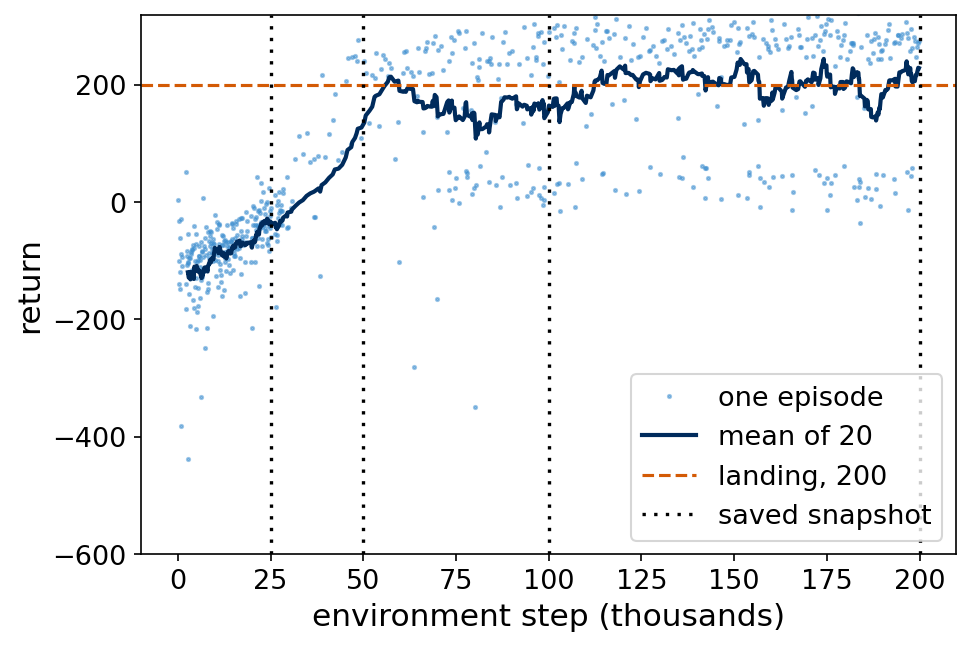

mean return of the last 50 training episodes: 208.3


In [ ]:
fig, ax = plt.subplots(figsize=(6.5, 4.2), layout="constrained")
x = np.array(ep_end_steps) / 1000; y = np.array(ep_returns); w = 20      # environment steps in thousands
ax.plot(x, y, ".", color=UJSky, ms=3, alpha=0.5, label="one episode")
ax.plot(x[w - 1:], np.convolve(y, np.ones(w) / w, "valid"), color=UJNavy, lw=2, label="mean of 20")
ax.axhline(200, color=DSOrange, ls="--", label="landing, 200")
for k, t in enumerate(SNAPSHOTS[1:]):
    ax.axvline(t / 1000, color="k", lw=1.6, ls=(0, (1, 2.5)), label="saved snapshot" if k == 0 else None)
ax.set_xlabel("environment step (thousands)"); ax.set_ylabel("return"); ax.set_ylim(-600, 320); ax.legend(loc="lower right")
save(fig, "fig_ll_dqn_learning"); plt.show()
NUMBERS["lastMean"] = round(float(np.mean(ep_returns[-50:])), 1)
print("mean return of the last 50 training episodes:", NUMBERS["lastMean"])

The return rises from the crashes of the random phase through a long phase in which the lander learns to hover and to avoid the crash penalty, and then to landings above 200. The dotted lines mark the saved snapshots. The return is the quantity to watch in reinforcement learning. The training loss is a poor indicator of progress, because the targets themselves change as the network improves.

*Exercise.* Train with `NU = 1.0`, which copies the network at every step and so removes the target network. Compare the learning curves.

## Watching the agent learn

We load each snapshot into a network and let it act greedily in one fixed test episode, with the same initial push, and record its return.

In [ ]:
def greedy_policy_from(params):
    net = make_qnet()
    with torch.no_grad():
        for p, v in zip(net.parameters(), params): p.copy_(v)
    return lambda s: int(net(torch.as_tensor(s)).argmax())

stage_returns = {}
for t in SNAPSHOTS:
    e = gym.make("LunarLander-v3"); s, _ = e.reset(seed=7); policy = greedy_policy_from(snapshots[t]); R, T = 0.0, 0
    while True:
        s, r, terminated, truncated, _ = e.step(policy(s)); R += r; T += 1
        if terminated or truncated: break
    stage_returns[t] = round(R, 1)
    print(f"snapshot after {t:7d} steps: return {R:7.1f} in a test episode of {T} steps")
NUMBERS["stageReturns"] = stage_returns

snapshot after       0 steps: return  -458.2 in a test episode of 62 steps
snapshot after   25000 steps: return   -42.4 in a test episode of 1000 steps
snapshot after   50000 steps: return   128.6 in a test episode of 864 steps
snapshot after  100000 steps: return   211.5 in a test episode of 167 steps
snapshot after  200000 steps: return   258.2 in a test episode of 278 steps


The untrained network fires one engine all the time and crashes. After 25 000 steps the network brakes with the main engine and hovers, which avoids the crash penalty but wastes fuel, and the test episode runs into the time limit. Later snapshots descend under control, straighten the lander and touch down between the flags. Three videos, each made of several episodes played one after another, show the random agent, the network after 25 000 training steps and the trained network.

In [13]:
rng_v = np.random.default_rng(5)
save_video(lambda s: int(rng_v.integers(4)), range(200, 300), "ll_dqn_random")
save_video(greedy_policy_from(snapshots[25_000]), range(200, 300), "ll_dqn_poor")
save_video(greedy_policy_from([p.detach() for p in q_net.parameters()]), range(200, 300), "ll_dqn_trained")
for name in ("ll_dqn_random", "ll_dqn_poor", "ll_dqn_trained"): display(Video(f"videos/{name}.mp4", embed=True, width=480))


ll_dqn_random: 6 episodes, 19.2 s


ll_dqn_poor: 1 episodes, 25.5 s


ll_dqn_trained: 4 episodes, 22.1 s


## The trained agent

trained agent over 50 new episodes: mean 242.3, landings with return >= 200: 40 of 50


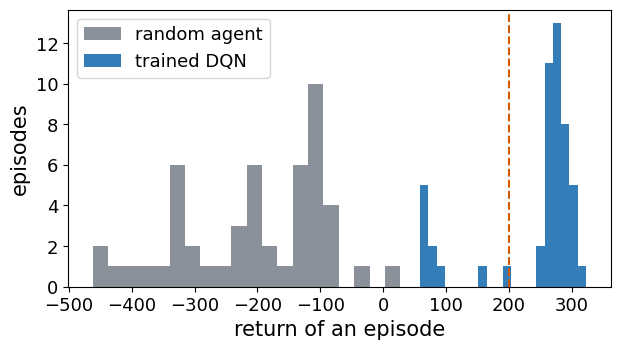

In [10]:
final_policy = greedy_policy_from([p.detach() for p in q_net.parameters()])
final_returns = [run_episode(final_policy, seed=1000 + k)[0] for k in range(50)]
print(f"trained agent over 50 new episodes: mean {np.mean(final_returns):.1f}, "
      f"landings with return >= 200: {sum(r >= 200 for r in final_returns)} of 50")
NUMBERS.update(finalMean=round(float(np.mean(final_returns)), 1), finalSolved=int(sum(r >= 200 for r in final_returns)))

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.hist(returns_random, bins=20, color=UJGray, alpha=0.7, label="random agent")
ax.hist(final_returns, bins=20, color=UJBlue, alpha=0.8, label="trained DQN")
ax.axvline(200, color=DSOrange, ls="--"); ax.set_xlabel("return of an episode"); ax.set_ylabel("episodes"); ax.legend()
save(fig, "fig_ll_dqn_returns"); plt.show()

*Exercise.* Train with `GAMMA = 0.9`. With such a short horizon the agent cares little about the landing bonus far in the future. Describe the behaviour of the trained agent.

## The learned control rule

The trained network assigns an action to every possible state of the lander, so it is a control rule that reacts to the current position, velocity and orientation. An engineer would design such a rule from the equations of motion. The network found its rule from rewards alone. We draw two slices of it. In the first the lander is upright above the pad, $x=v_x=\varphi=\omega=0$, and we vary the height $y$ and the vertical velocity $v_y$. In the second it is at mid height, $y=0.7$, at rest, and we vary the angle $\varphi$ and the angular velocity $\omega$. Each pixel shows the greedy action, and the contour lines show the predicted value $\max_aQ_\theta(s,a)$.

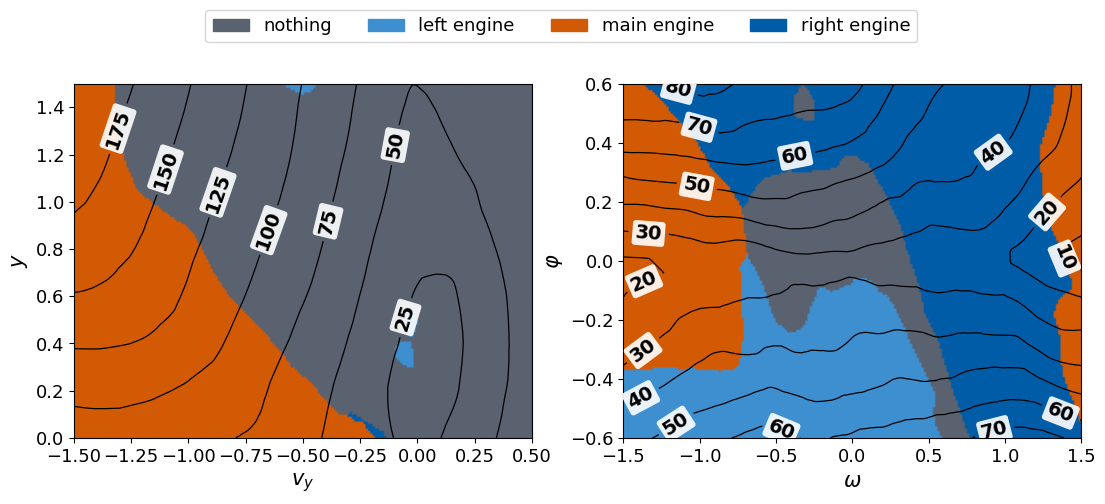

In [12]:
def policy_slice(fixed, ix, iy, xs, ys):
    # greedy action and max Q on a 2D slice of the 8D state space; all other coordinates as in `fixed`
    S = np.tile(np.array(fixed, np.float32), (len(ys), len(xs), 1))
    S[..., ix] = xs[None, :]; S[..., iy] = ys[:, None]
    with torch.no_grad(): q = q_net(torch.as_tensor(S.reshape(-1, N_STATE))).numpy().reshape(len(ys), len(xs), N_ACT)
    return q.argmax(-1), q.max(-1)

from matplotlib.colors import ListedColormap
cmap4 = ListedColormap([UJGray, UJSky, DSOrange, UJBlue])
fig, axs = plt.subplots(1, 2, figsize=(13, 4.6))
panels = ((3, 1, np.linspace(-1.5, 0.5, 201), np.linspace(0.0, 1.5, 151), [0, 0, 0, 0, 0, 0, 0, 0], "$v_y$", "$y$"),
          (5, 4, np.linspace(-1.5, 1.5, 201), np.linspace(-0.6, 0.6, 151), [0, 0.7, 0, 0, 0, 0, 0, 0], r"$\omega$", r"$\varphi$"))
for ax, (ix, iy, xs, ys, fixed, xl, yl) in zip(axs, panels):
    act, val = policy_slice(fixed, ix, iy, xs, ys)
    ax.imshow(act, origin="lower", extent=(xs[0], xs[-1], ys[0], ys[-1]), aspect="auto", cmap=cmap4, vmin=-0.5, vmax=3.5)
    cs = ax.contour(xs, ys, val, levels=8, colors="k", linewidths=0.9)
    for txt in ax.clabel(cs, fontsize=14, fmt="%.0f", inline_spacing=8):    # labels on a white background
        txt.set_bbox(dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.9)); txt.set_fontweight("bold")
    ax.set_xlabel(xl); ax.set_ylabel(yl)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in (UJGray, UJSky, DSOrange, UJBlue)]
fig.legend(handles, ["nothing", "left engine", "main engine", "right engine"], loc="upper center", ncol=4, bbox_to_anchor=(0.5, 1.06))
save(fig, "fig_ll_dqn_phase"); plt.show()

In the $(v_y,y)$ slice the network fires the main engine when the lander falls fast for its height and lets it fall freely otherwise. In the $(\omega,\varphi)$ slice the choice between the left and the right engine depends mainly on the sign of the tilt, and the boundary between them is slanted, so the network reacts to a combination of angle and angular velocity. At large angular velocities it fires the main engine. The slices are only two cuts through a rule that depends on eight numbers, and the network was never told any of these rules.

*Exercise.* Draw the $(x,v_x)$ slice at $y=0.7$ and describe how the lander is steered towards the pad.

In [14]:
# Write the numbers quoted in the text to files used for typesetting (LaTeX macros such as \dqnfinalMean).
with open("results/numbers_dqn.json", "w") as f: json.dump(NUMBERS, f, indent=1)
with open("results/nb_numbers_dqn.tex", "w") as f:
    for k, v in NUMBERS.items():
        if not isinstance(v, dict): f.write(f"\\newcommand{{\\dqn{k}}}{{{v}}}\n")
    for t, v in NUMBERS["stageReturns"].items():
        f.write(f"\\newcommand{{\\dqnStage{'ABCDE'[SNAPSHOTS.index(t)]}}}{{{v}}}\n")
print(NUMBERS)

{'randMean': -203.3, 'qParams': 69124, 'trainMinutes': 11.5, 'nEpisodes': 667, 'lastMean': 208.3, 'stageReturns': {0: np.float64(-458.2), 25000: np.float64(-42.4), 50000: np.float64(128.6), 100000: np.float64(211.5), 200000: np.float64(258.2)}, 'finalMean': 242.3, 'finalSolved': 40}
